# 方法对比 — SimpleLines 5 组线条 (blinking_500pps)

15 条水平线（5 组 × 3 条，组内间距 100/150/200/250/300 nm）；3 态闪烁 500 pps；
模拟器真实 PSF（NA1.49/680 + Z11/Z6 像差）；EMCCD（offset 486 / gain 148）；前 500 帧。

**3×4 网格**（每行 4 格）：
1. **GT**(90nm 模糊) · **WF**(均值) · **SOFI-2** · **SOFI-3**
2. **preRL(4)** · **preRL(4)+累积量** · **preRL(15)** · **preRL(15)+累积量**（累积量 = SACD 式：时间滞后1 对 `|I−0.8μ|`）
3. **SACD**（preRL4/15 + 累积量 + post-RL `(细PSF)²`）· **RIED**（preRL4/15 + RiedSofit + 稀疏反卷积）

评估：垂直剖面（横切水平线）+ 每组 3 线可分辨调制 (P−V)/(P+V) + 与 GT 的 SSIM。
preRL→上采样输出只算一次（iter∈{4,15}），供 累积量 / SACD / RIED 复用。


In [7]:
# ============ 配置 ============
SRC = r"E:\CodingProj\Data\Simulated_Datasets\lines\simulation_1000f_0p10s_simple_lines_no_blinking_500pps_emccd_160nm.tif"
GT_PATH = r"E:\CodingProj\Data\Simulated_Datasets\lines\simulation_1000f_0p10s_simple_lines_no_blinking_2pps_emccd_160nm_gt_gauss_sresx16.tif"
GAIN, OFFSET, PIXEL_NM = 148, 486, 160
CROP = (0, 63)
RIED_FRAMES = 500             # 统一用前 500 帧
NA, WAVELENGTH = 1.49, 680.0   # 模拟器真实 PSF
EC_FWHM_NM = 90.0              # GT 渲染模糊宽度
SACD_SUB = 0.8                 # SACD 累积量 subfactor (|I - sub·μ|)
ITERS = [4, 15]                # pre-RL 迭代次数 (两种都做)

# ============ 导入 ============
import os, sys
import numpy as np
import matplotlib.pyplot as plt
import tifffile
from scipy.ndimage import map_coordinates, gaussian_filter
from skimage.metrics import structural_similarity as ssim
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

sys.path.insert(0, r"E:\CodingProj\SMLIE\Projects\Smile_Codes\Simulation_Smile")
sys.path.insert(0, r"E:\CodingProj\SMLIE\Projects\Smile_Codes\Py_Smile")
from smlm.io import load_raw
from smlm.camera import sCMOS
from smlm.imgprocess import (Pipeline, Crop, SelectFrames, GaussianFilter,
                             FourierUpsample, RL3D, Dehotpixel,
                             CumulantSofit, RiedSofit, SparseDeconv)
from simulation_smile.optics.circular import CircularAperturePSF

# ============ 工具 ============
def matched_psf(px_nm, n):
    """模拟器真实 PSF (含像差 Z11/Z6), 采样到 px_nm 网格, 中心取 n×n, 归一化。"""
    ov = WAVELENGTH / (2.0 * NA * px_nm)
    m = CircularAperturePSF(na=NA, wavelength=WAVELENGTH, pupil_size=128,
                            oversample=ov, zernike={11: 0.07, 6: 0.02}, n_channels=1)
    K = m.psf_at(0.0); c = K.shape[0] // 2; h = n // 2
    k = K[c - h: c + h + 1, c - h: c + h + 1]
    return (k / k.sum()).astype(np.float32)

def norm01(a):
    a = a - a.min(); mx = a.max()
    return a / mx if mx > 0 else a

def resample(img, n):
    h, w = img.shape
    yy = (np.arange(n) + 0.5) * h / n - 0.5
    xx = (np.arange(n) + 0.5) * w / n - 0.5
    YY, XX = np.meshgrid(yy, xx, indexing="ij")
    return map_coordinates(img, (YY, XX), order=1, mode="constant", cval=0.0)

def vs_gt(z):
    """z 与 GT 的 SSIM (z 重采样到 GT 网格)。"""
    a = resample(np.asarray(z, float), gt_sres.shape[0])
    return ssim(norm01(a), norm01(gt_sres), data_range=1.0)

group_cy = {100: [3120, 3220, 3320], 150: [3820, 3970, 4120], 200: [4620, 4820, 5020],
            250: [5520, 5770, 6020], 300: [6520, 6820, 7120]}
YG = np.arange(3000, 7300, 2.0)

def profile_of(z, ps):
    """垂直剖面 (横切水平线): (y_grid, 行均值), 行 r 的 y=(r+0.5)*ps。"""
    return (np.arange(z.shape[0]) + 0.5) * ps, z.mean(1)

print("配置就绪")


配置就绪


In [8]:
# ============ 加载数据 + GT + 匹配真核 ============
raw = load_raw(SRC)
H0, W0 = raw.data.shape[1:]
image = sCMOS(gain_map=np.full((H0, W0), GAIN),
              offset_map=np.full((H0, W0), OFFSET)).process(raw, pixel_size=PIXEL_NM)
ried_stack = Pipeline(Crop(y=CROP, x=CROP), SelectFrames(start=0, stop=RIED_FRAMES),
                      Dehotpixel())(image)
wf = ried_stack.data.mean(0)                       # 宽场均值基线 (160nm)

gt_sres = tifffile.imread(GT_PATH).astype(np.float64)
gt_ps = PIXEL_NM / 16
sigma_gt = EC_FWHM_NM / (2 * np.sqrt(2 * np.log(2))) / gt_ps
gt_sres = gaussian_filter(gt_sres, sigma=sigma_gt)   # 模糊到 EC 有效宽度 (渲染参考)

# 反卷积核 = 数据自身成像 PSF (匹配真核含像差):
psf_nat   = matched_psf(PIXEL_NM, 33)               # 原生 160nm (pre-RL; 帧 63px 内)
psf_fine  = matched_psf(PIXEL_NM / 2, 65)           # 细 80nm (SACD post 用 ^2)
psf_fine2 = (psf_fine ** 2); psf_fine2 = (psf_fine2 / psf_fine2.sum()).astype(np.float32)
psf_quad  = matched_psf(PIXEL_NM / 4, 65)           # 40nm 匹配真核(含像差): SACD 用 ^2,
                                                    #   RIED 后置反卷积用 psf_quad 本身 (RIED scale=1)
psf_quad2 = (psf_quad ** 2); psf_quad2 = (psf_quad2 / psf_quad2.sum()).astype(np.float32)

print("ried_stack:", ried_stack.data.shape, "@", ried_stack.pixel_size, "nm/px")
print("GT:", gt_sres.shape, "@", gt_ps, "nm/px | 核: 原生", psf_nat.shape,
      "细", psf_fine.shape, "quad(RIED/SACD)", psf_quad.shape)


ried_stack: (500, 63, 63) @ 160 nm/px
GT: (1024, 1024) @ 10.0 nm/px | 核: 原生 (33, 33) 细 (65, 65) quad(RIED/SACD) (65, 65)


## 0. 方法前向计算（预处理 + 各方法）

统一算出后面所有对比要用的图：`GT / WF / SOFI-2 / SOFI-3 / preRL(4,15) / preRL+Cum /
SACD(preRL4,15) / RIED(preRL4,15)`。其中 `UPS[it]` 缓存了两种 preRL 的上采样结果，
后面的对比直接复用，不重复计算。

In [9]:
# ============ 计算所有方法 (复用: preRL→上采样 每种 iter 只算一次) ============
# 统一走 Transform: ImageStack 进保 pixel 链; ndarray 进可当函数直接用 (鸭子类型)。
from dataclasses import replace

SACD_ORDER = 2                       # SACD 累积量阶数 (需要时可提至 3/4)
IMGS, PXS = {}, {}                   # 名字 -> (图像, 像素nm)

# ---- Row1: GT / WF / SOFI-2 / SOFI-3 ----
IMGS["GT"] = gt_sres;      PXS["GT"] = gt_ps
IMGS["WF"] = wf;           PXS["WF"] = float(PIXEL_NM)
for order, lab in [(2, "SOFI-2"), (3, "SOFI-3")]:
    # 外层 np.abs: 经典 SOFI 时间累积量(逐路中心化后)可含负值; SACD 后置前取 |·|、RIED
    # 内部 use_abs=True —— 显示按强度图约定都为正 → SOFI 同样取 |·| 才公平 (只影响幅度, 结构不变)。
    IMGS[lab] = np.abs(Pipeline(FourierUpsample(2, taper=False),
                                CumulantSofit(order=order, subseq=250))(ried_stack).data[0])
    PXS[lab] = ried_stack.pixel_size / 2

# ---- Row2+3: preRL(iter) → 上采样 → SACD式累积量 → SACD / RIED ----
UPS = {}                                 # 复用的上采样 ImageStack@80nm
for it in ITERS:
    rl_stack = RL3D(psf_nat, iterations=it)(ried_stack)          # preRL @原生160nm
    IMGS[f"preRL{it}"] = rl_stack.data.mean(0); PXS[f"preRL{it}"] = float(PIXEL_NM)

    up = FourierUpsample(2, lateral=True)(rl_stack)              # @80nm (ImageStack 保 pixel)
    up = replace(up, data=np.clip(up.data, 0, None))             # 负值清零 (SACDm)
    UPS[it] = up

    # SACD 式累积量 = CumulantSofit(subfactor=SACD_SUB, take_abs=True)
    #   (SACD 核心, 可任意阶; ndarray 鸭子调用, 与老 abs-lag1 时间对一致)
    cum = np.abs(CumulantSofit(order=SACD_ORDER, lags=tuple(range(SACD_ORDER)),
                               subseq=up.data.shape[0], subfactor=SACD_SUB,
                               take_abs=True)(up.data))
    IMGS[f"preRL{it}+Cum"] = cum; PXS[f"preRL{it}+Cum"] = ried_stack.pixel_size / 2

    # SACD = 累积量 → 二次 ×2 上采样(40nm) → post-RL (RL3D 鸭子: 2D ndarray 直接反卷积)
    #   (后置前多加一次上采样, 使 SACD 终图与 RIED 同为 40nm 网格 —— 公平对比像素级)
    cum40 = FourierUpsample(2, lateral=True)(cum)              # @40nm
    IMGS[f"SACD(preRL{it})"] = RL3D(psf_quad2, iterations=8)(cum40)
    PXS[f"SACD(preRL{it})"] = ried_stack.pixel_size / 4

    # RIED = RiedSofit(熵) + SparseDeconv (ImageStack 链: 自动 2×虚拟网格→40nm)
    #   subfactor 用 SACD_SUB(0.8) 与 SACD 对齐; 后置核用匹配真核 psf_quad(@40nm, 含像差)
    #   —— 与 SACD 同一 PSF 模型。原用 140nm 高斯(无像差)不匹配数据 PSF → 分辨率恢复差
    #   (诊断: 300nm 调制 0.36→0.999)。RIED 参考实现后置核即该网格 PSF 本身 (scale=1, 不平方)。
    IMGS[f"RIED(preRL{it})"] = Pipeline(
        RiedSofit(subfactor=SACD_SUB, entropy=True),
        SparseDeconv(psf_quad, fidelity=150, sparsity=0.2,
                     iter_bregman=100, iterations=30))(up).data[0]
    PXS[f"RIED(preRL{it})"] = ried_stack.pixel_size / 4

print("已计算:", list(IMGS))


已计算: ['GT', 'WF', 'SOFI-2', 'SOFI-3', 'preRL4', 'preRL4+Cum', 'SACD(preRL4)', 'RIED(preRL4)', 'preRL15', 'preRL15+Cum', 'SACD(preRL15)', 'RIED(preRL15)']


## 对比 1：SACD 相关前 `abs` 开关 × subfactor {0.5, 0.8, 1.0}

SACD 核心 = 对 `|I − sub·μ|` 做时间滞后累积量，再取 `|·|` 后上采样、后卷积。这里区分两层绝对值：

- **内层 `take_abs`（相关前）**：相关对象用 `|I − sub·μ|`（开）还是带号的 `I − sub·μ`（关）；
- **外层 `|·|`（相关后）**：无论内层开关，相关输出在后置前一律再取一次 `|·|`（SACDm 约定）；
- **subfactor**：决定减掉多少时间均值 μ，越小 → 残留 DC 越多、基线越高。

三张图依次为：累积量 / SACD 终图、单像素时间轨迹、垂直剖面。

累积量 (preRL15) —— 图/终图用 相关后|·|; 下方是 相关输出(带号) 统计:
  sub=0.5: 内层abs开 相关输出恒正 mean=4599 | 内层abs关 相关输出 mean=4432 min=-24 负=15%  (后置前再取|·|)
  sub=0.8: 内层abs开 相关输出恒正 mean=1229 | 内层abs关 相关输出 mean=707 min=-216 负=24%  (后置前再取|·|)
  sub=1.0: 内层abs开 相关输出恒正 mean=727 | 内层abs关 相关输出 mean=-3 min=-1157 负=55%  (后置前再取|·|)
组间距    0.5      开0.5      关0.8      开0.8      关1.0      开1.0      关
100nm       -0.226     -0.233     -0.180     -0.235      0.140      0.130
150nm       -0.085     -0.115      0.022     -0.119      0.127      0.057
200nm        0.234      0.248      0.130      0.240      0.063     -0.030
250nm        0.597      0.625      0.451      0.620      0.363      0.240
300nm        0.998      1.000      0.975      1.000      0.886      0.677
SSIM@GT: sub=0.5 开:0.716   sub=0.5 关:0.714   sub=0.8 开:0.719   sub=0.8 关:0.714   sub=1.0 开:0.712   sub=1.0 关:0.705


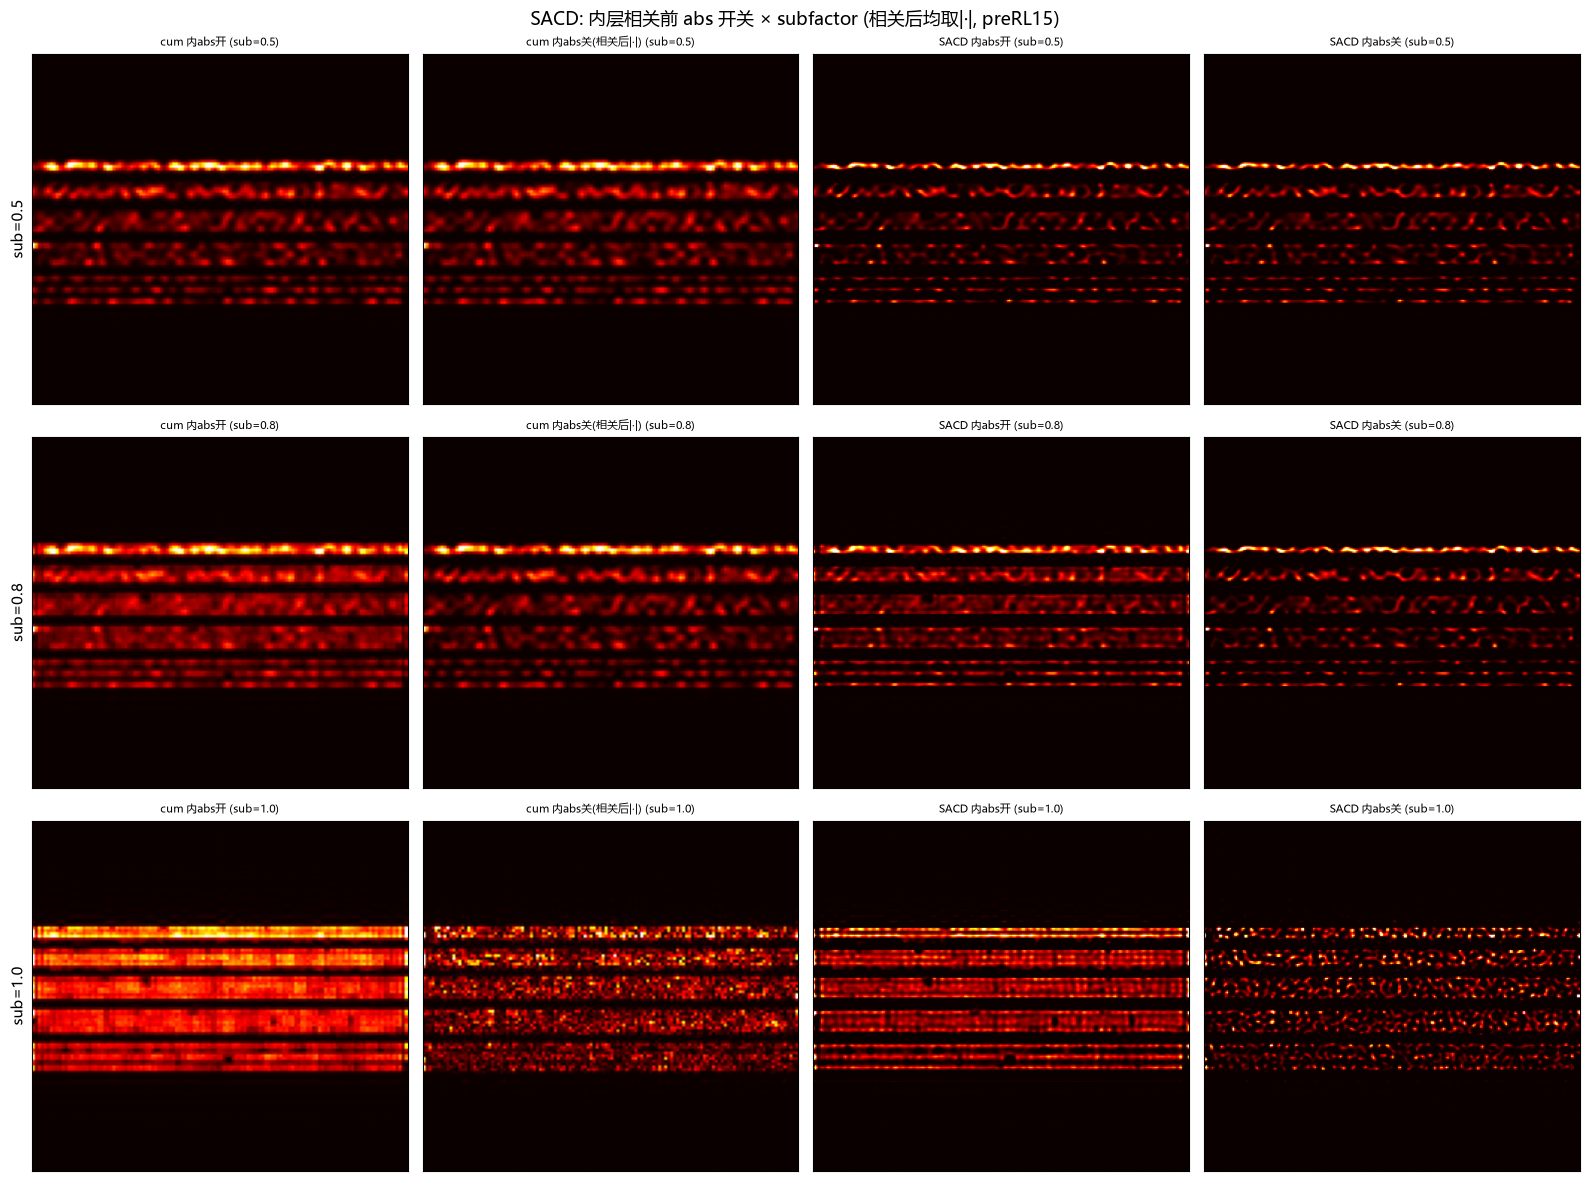

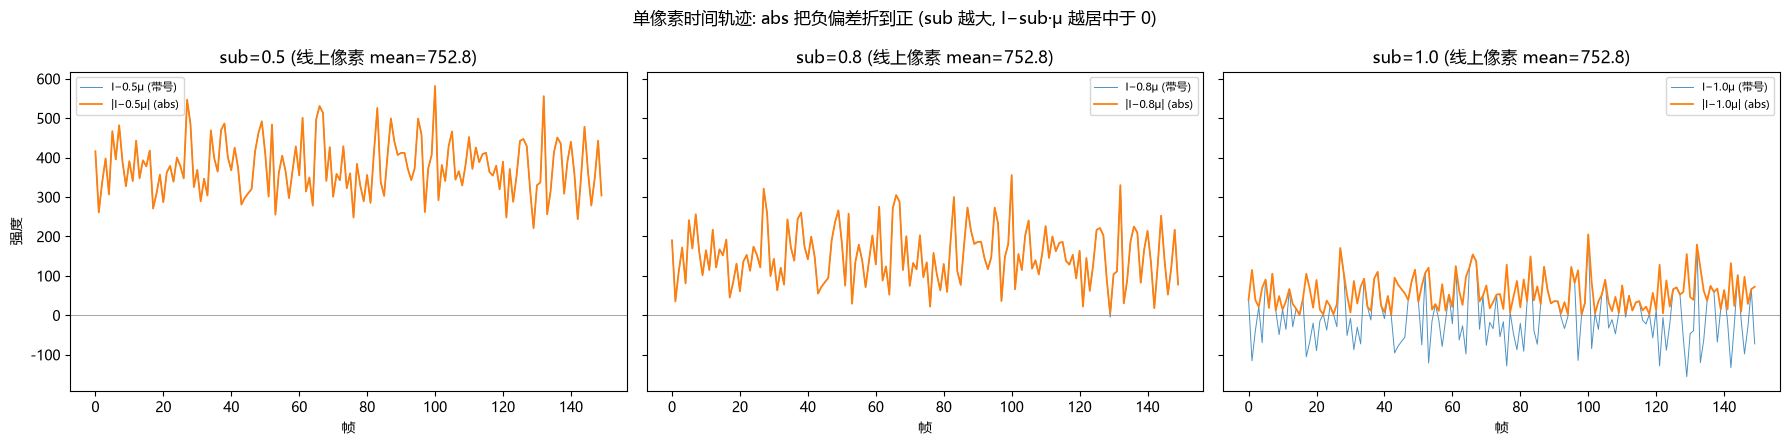

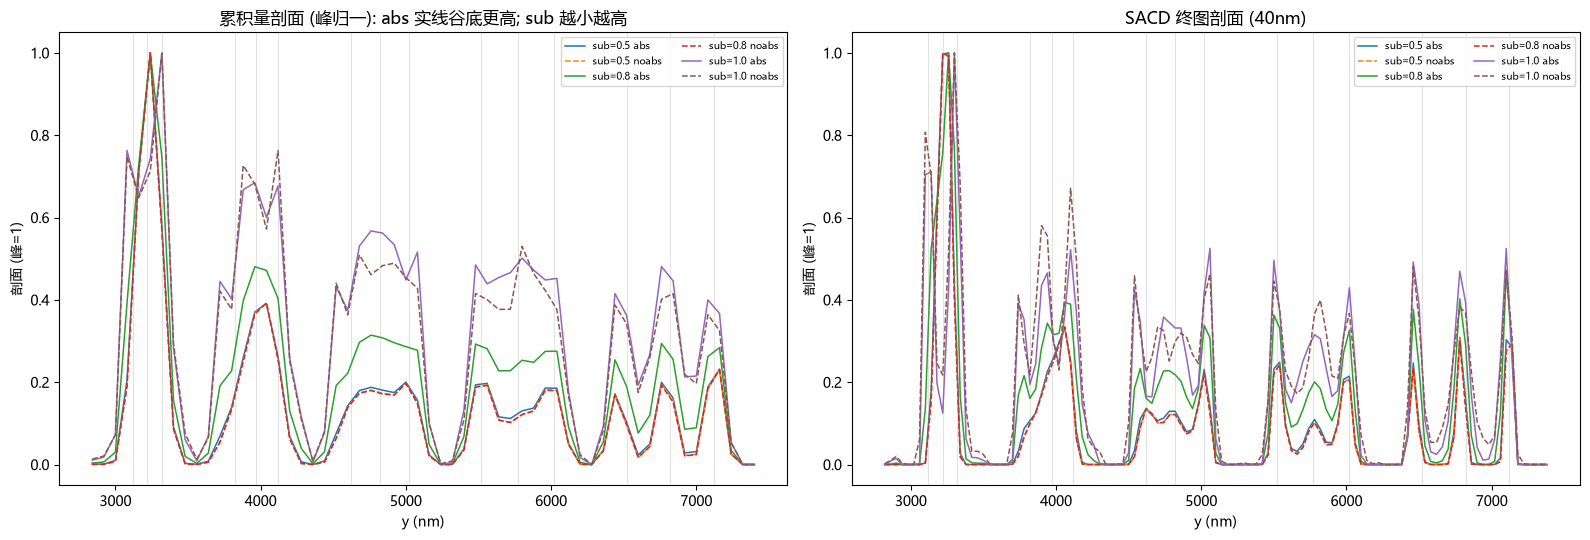

In [6]:
# ============ SACD: 相关前 abs 开/关 × subfactor {0.5,0.8,1.0} (preRL15, 复用 UPS[15]) ============
# 两层 abs 分清:
#   ① 内层 take_abs (相关前): |I - sub·μ|  vs 带号 I - sub·μ (决定相关对象);
#   ② 外层 |·| (相关后, SACDm 的 cum=abs(cumulant(...))): 无论内层开/关, 相关输出在后置前
#      一律再取 |·| —— 本 cell 的 cum 列与终图都基于这个相关后绝对值。
# sub 决定减多少时间均值: sub 越小残留 DC 越多(基线越高); sub=1 完全中心化。
_UP = UPS[15].data                                  # @80nm, preRL15 上采样
_SUBA = [0.5, 0.8, 1.0]

def _sacd_core(subfactor, take_abs):
    c0 = CumulantSofit(order=SACD_ORDER, lags=tuple(range(SACD_ORDER)),
                       subseq=_UP.shape[0], subfactor=subfactor,
                       take_abs=take_abs)(_UP)                 # 相关输出 (内层关时带号)
    c = np.abs(c0)                                            # 外层: 相关后 |·| (SACDm)
    c40 = FourierUpsample(2, lateral=True)(c)                 # @40
    return c0, c, RL3D(psf_quad2, iterations=8)(c40)          # (相关输出, |cum|, SACD@40)

_CA0, _CA, _FA = {}, {}, {}                    # key=(sub, take_abs)
for _s in _SUBA:
    for _ab in (True, False):
        _CA0[(_s, _ab)], _CA[(_s, _ab)], _FA[(_s, _ab)] = _sacd_core(_s, _ab)

def _modA(z, ps):
    yv, vv = profile_of(z, ps)
    prof = np.interp(YG, yv, vv)
    g = np.interp(YG, *profile_of(gt_sres, gt_ps))
    cc = np.correlate(prof - prof.mean(), g - g.mean(), mode="full")
    prof = np.roll(prof, -(np.argmax(cc) - (len(cc) // 2)))
    out = {}
    for s, ys in group_cy.items():
        P = np.mean([np.interp(yy, YG, prof) for yy in ys])
        V = np.mean([np.interp((ys[0] + ys[1]) / 2, YG, prof),
                     np.interp((ys[1] + ys[2]) / 2, YG, prof)])
        out[s] = (P - V) / (P + V + 1e-12)
    return out

print("累积量 (preRL15) —— 图/终图用 相关后|·|; 下方是 相关输出(带号) 统计:")
for _s in _SUBA:
    _on, _off = _CA0[(_s, True)], _CA0[(_s, False)]
    print(f"  sub={_s}: 内层abs开 相关输出恒正 mean={_on.mean():.0f}"
          f" | 内层abs关 相关输出 mean={_off.mean():.0f} min={_off.min():.0f} "
          f"负={100 * (_off < 0).mean():.0f}%  (后置前再取|·|)")
_mA = {k: _modA(_FA[k], ried_stack.pixel_size / 4) for k in _FA}
print(f"{'组间距':<7}" + "".join(f"{s:.1f}{'开' if ab else '关':>7}" for s in _SUBA for ab in (True, False)))
for sg in group_cy:
    print(f"{str(sg)+'nm':<7}" + "".join(f"{_mA[(s, ab)][sg]:>11.3f}"
                                         for s in _SUBA for ab in (True, False)))
print("SSIM@GT: " + "   ".join(
    f"sub={s} {('开' if ab else '关')}:{vs_gt(_FA[(s, ab)]):.3f}"
    for s in _SUBA for ab in (True, False)))

# ---- 图1: 累积量 / 终图 × abs × sub (行=sub, 列=cum开|cum关|final开|final关) ----
# cum 列 = 相关后 |·| (对齐 SACDm cum=abs(cumulant)); 内层 take_abs 差异仍在结果里体现。
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i, _s in enumerate(_SUBA):
    for j, (key, ttl) in enumerate([
            ((_s, True), "cum 内abs开"), ((_s, False), "cum 内abs关(相关后|·|)"),
            ((_s, True), "SACD 内abs开"), ((_s, False), "SACD 内abs关")]):
        z = (_CA[key] if j < 2 else _FA[key])
        v = np.percentile(np.abs(z), 99.9)
        axes[i, j].imshow(z, cmap="hot", aspect="auto", vmin=0, vmax=v)
        axes[i, j].set_title(f"{ttl} (sub={_s})", fontsize=8)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    axes[i, 0].set_ylabel(f"sub={_s}", fontsize=11)
plt.suptitle("SACD: 内层相关前 abs 开关 × subfactor (相关后均取|·|, preRL15)", fontsize=13)
plt.tight_layout(); plt.show()

# ---- 图2: 单像素时间轨迹 × sub (abs 折正负偏差) ----
_mu = _UP.mean(0)
_r, _c = np.unravel_index(int(np.argmax(_mu)), _mu.shape)   # 同一"线上"最亮像素
_tt = np.arange(_UP.shape[0]); _N = 150
fig2, axs = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, _s in zip(axs, _SUBA):
    _ctr = _UP[:, _r, _c] - _s * _mu[_r, _c]
    ax.plot(_tt[:_N], _ctr[:_N], lw=0.7, alpha=0.8, label=f"I−{_s}μ (带号)")
    ax.plot(_tt[:_N], np.abs(_ctr[:_N]), lw=1.3, label=f"|I−{_s}μ| (abs)")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"sub={_s} (线上像素 mean={_mu[_r, _c]:.1f})")
    ax.set_xlabel("帧"); ax.legend(fontsize=8)
axs[0].set_ylabel("强度")
plt.suptitle("单像素时间轨迹: abs 把负偏差折到正 (sub 越大, I−sub·μ 越居中于 0)", fontsize=12)
plt.tight_layout(); plt.show()

# ---- 图3: 垂直剖面 (累积量 & 终图), sub=颜色 / abs=线型 ----
def _profB(z, ps, ylo=2800.0, yhi=7400.0):
    y = (np.arange(z.shape[0]) + 0.5) * ps
    v = z.mean(1)
    m = (y >= ylo) & (y <= yhi)
    return y[m], v[m]

fig3, axs = plt.subplots(1, 2, figsize=(16, 5.5))
for _s in _SUBA:
    for _ab, ls in ((True, "-"), (False, "--")):
        y, v = _profB(_CA[(_s, _ab)], ried_stack.pixel_size / 2)
        axs[0].plot(y, v / np.max(v), ls=ls, lw=1.1, label=f"sub={_s} {'abs' if _ab else 'noabs'}")
        y2, v2 = _profB(_FA[(_s, _ab)], ried_stack.pixel_size / 4)
        axs[1].plot(y2, v2 / np.max(v2), ls=ls, lw=1.1,
                    label=f"sub={_s} {'abs' if _ab else 'noabs'}")
for a in axs:
    for ys in group_cy.values():
        for yy in ys:
            a.axvline(yy, color="grey", lw=0.4, alpha=0.4)
    a.set_xlabel("y (nm)"); a.set_ylabel("剖面 (峰=1)"); a.legend(fontsize=7, ncol=2)
axs[0].set_title("累积量剖面 (峰归一): abs 实线谷底更高; sub 越小越高")
axs[1].set_title("SACD 终图剖面 (40nm)")
plt.tight_layout(); plt.show()


## 对比 2：subfactor 扫描 0.5 / 0.8 / 1.0（均 `take_abs=True`）

固定相关前取 `|·|`，只变 subfactor，观察累积量基线（残留 DC）与 SACD 终图分辨率的权衡：
sub=1 完全中心化（真涨落），sub<1 保留亮度加权基底。给出累积量 / 终图图集与剖面对比。

In [ ]:
# ============ SACD: subfactor 扫描 0.5 / 0.8 / 1.0 (均 take_abs=True, 复用 UPS[15]) ============
# sub 决定相关前减去多少时间均值:
#   sub=1 → |I − μ| 完全中心化(真 MAD 涨落), 残留 DC 最少;
#   sub<1 → 只减部分均值 → |I − sub·μ| 残留 (1−sub)·μ 的 DC → 相关结果带更强亮度加权基底。
_SUBS = [0.5, 0.8, 1.0]
_cS, _fS = {}, {}
for _s in _SUBS:
    _cS[_s] = np.abs(CumulantSofit(order=SACD_ORDER, lags=tuple(range(SACD_ORDER)),
                                   subseq=_UP.shape[0], subfactor=_s,
                                   take_abs=True)(_UP))                # cum@80
    _fS[_s] = RL3D(psf_quad2, iterations=8)(
        FourierUpsample(2, lateral=True)(_cS[_s]))                      # SACD@40

def _mod2(z, ps):
    yv, vv = profile_of(z, ps)
    prof = np.interp(YG, yv, vv)
    g = np.interp(YG, *profile_of(gt_sres, gt_ps))
    cc = np.correlate(prof - prof.mean(), g - g.mean(), mode="full")
    prof = np.roll(prof, -(np.argmax(cc) - (len(cc) // 2)))
    out = {}
    for sg, ys in group_cy.items():
        P = np.mean([np.interp(yy, YG, prof) for yy in ys])
        V = np.mean([np.interp((ys[0] + ys[1]) / 2, YG, prof),
                     np.interp((ys[1] + ys[2]) / 2, YG, prof)])
        out[sg] = (P - V) / (P + V + 1e-12)
    return out

_mS = {s: _mod2(_fS[s], ried_stack.pixel_size / 4) for s in _SUBS}
print("sub 扫描 (take_abs=True, preRL15): 累积量均值 " +
      ", ".join(f"sub={s}: {_cS[s].mean():.0f}" for s in _SUBS) +
      "  (sub 越小 → |I−sub·μ| 残留 DC 越多 → 均值/基线越大)")
print(f"{'组间距':<8}" + "".join(f"sub={s:>8}" for s in _SUBS))
for sg in group_cy:
    print(f"{str(sg)+'nm':<8}" + "".join(f"{_mS[s][sg]:>13.3f}" for s in _SUBS))
print("SSIM@GT: " + "   ".join(f"sub={s}: {vs_gt(_fS[s]):.3f}" for s in _SUBS))

# ---- 图: 累积量(上) & 终图(下) × sub ----
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, s in enumerate(_SUBS):
    axes[0, j].imshow(_cS[s], cmap="hot", vmin=0, vmax=np.percentile(_cS[s], 99.9),
                      aspect="auto")
    axes[0, j].set_title(f"cum sub={s}")
    axes[1, j].imshow(_fS[s], cmap="hot", vmin=0, vmax=np.percentile(_fS[s], 99.9),
                      aspect="auto")
    axes[1, j].set_title(f"SACD final sub={s} (40nm)")
    for a in (axes[0, j], axes[1, j]):
        a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel("累积量@80"); axes[1, 0].set_ylabel("SACD@40")
plt.suptitle("SACD subfactor 扫描 (take_abs=True, preRL15)", fontsize=12)
plt.tight_layout(); plt.show()

# ---- 剖面对比: sub 越小谷底 DC 越高 ----
def _prof3(z, ps, ylo=2800.0, yhi=7400.0):
    y = (np.arange(z.shape[0]) + 0.5) * ps
    v = z.mean(1)
    m = (y >= ylo) & (y <= yhi)
    return y[m], v[m]

fig2, axs = plt.subplots(1, 2, figsize=(14, 5))
for s in _SUBS:
    y, v = _prof3(_cS[s], ried_stack.pixel_size / 2)
    axs[0].plot(y, v / np.max(v), lw=1.1, label=f"sub={s} cum")
    y2, v2 = _prof3(_fS[s], ried_stack.pixel_size / 4)
    axs[1].plot(y2, v2 / np.max(v2), lw=1.1, label=f"sub={s} final")
for a in axs:
    for ys in group_cy.values():
        for yy in ys:
            a.axvline(yy, color="grey", lw=0.4, alpha=0.4)
    a.legend(fontsize=8); a.set_xlabel("y (nm)"); a.set_ylabel("剖面 (峰=1)")
axs[0].set_title("累积量剖面 (峰归一): sub 越小 → 谷底/DC 越高")
axs[1].set_title("SACD 终图剖面 (40nm)")
plt.tight_layout(); plt.show()


## 方法总览：3×4 对比图

`GT / WF / SOFI-2 / SOFI-3 / preRL(次) ± 累积量 / SACD / RIED` 一览（同一 500pps 数据）。

In [ ]:
# ============ 3×4 方法对比图 ============
ROWS = [
    ("宽场 / 经典涨落",    ["GT", "WF", "SOFI-2", "SOFI-3"]),
    ("preRL(次) ± 累积量", ["preRL4", "preRL4+Cum", "preRL15", "preRL15+Cum"]),
    ("SACD / RIED(后置反卷积)", ["SACD(preRL4)", "SACD(preRL15)",
                              "RIED(preRL4)", "RIED(preRL15)"]),
]
fig, axes = plt.subplots(3, 4, figsize=(17, 12))
for ri, (rlab, keys) in enumerate(ROWS):
    for ci, k in enumerate(keys):
        z, ps = IMGS[k], PXS[k]
        ax = axes[ri, ci]
        v = np.percentile(z, 99.9)
        ax.imshow(np.clip(z, 0, v), cmap="hot", aspect="auto",
                  extent=(0, z.shape[1] * ps, z.shape[0] * ps, 0))
        ax.set_title(f"{k} ({ps:.0f} nm/px)", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        for ys in group_cy.values():
            for yy in ys:
                ax.axhline(yy, color="w", lw=0.3, alpha=0.25)
    axes[ri, 0].set_ylabel(rlab, fontsize=11, rotation=90, labelpad=10)
plt.suptitle("blinking_500pps 水平线组 (5组×3线, 组内 100-300nm) — 方法对比", fontsize=13)
plt.tight_layout(rect=(0.01, 0, 1, 0.99)); plt.show()


## 评估：垂直剖面 + 每组可分辨调制 + 与 GT 的 SSIM

调制 `(峰−谷)/(峰+谷)` 越大越可分辨；SSIM 衡量与 GT 的整体相似度。

In [ ]:
# ============ 评估: 垂直剖面 + 每组可分辨调制 + 与GT相似度 ============
# 垂直剖面 (横切水平线), 与 GT 做互相关整体对齐后, 测每组 3 线的峰谷调制。
ALL_KEYS = [k for row in ROWS for k in row[1]]
yv_gt, vv_gt = profile_of(gt_sres, gt_ps)
profiles = {}
for k in ALL_KEYS:
    yv, vv = profile_of(IMGS[k], PXS[k])
    prof = np.interp(YG, yv, vv)
    g = np.interp(YG, yv_gt, vv_gt)
    cc = np.correlate(prof - prof.mean(), g - g.mean(), mode="full")
    prof = np.roll(prof, -(np.argmax(cc) - (len(cc) // 2)))
    profiles[k] = prof

def modulation(prof):
    out = {}
    for s, ys in group_cy.items():
        P = np.mean([np.interp(yy, YG, prof) for yy in ys])
        V = np.mean([np.interp((ys[0] + ys[1]) / 2, YG, prof),
                     np.interp((ys[1] + ys[2]) / 2, YG, prof)])
        out[s] = (P - V) / (P + V + 1e-12)
    return out

mods = {k: modulation(profiles[k]) for k in ALL_KEYS}
print("调制 (峰-谷)/(峰+谷), 越大越可分辨 (GT≈0.99@300nm):")
print(f"{'间距':<7}" + "".join(f"{k:>13}" for k in ALL_KEYS))
for s in group_cy:
    print(f"{str(s)+'nm':<7}" + "".join(f"{mods[k][s]:>13.3f}" for k in ALL_KEYS))

print("\n与 GT 的 SSIM (z 重采样到 GT 网格):")
print(f"{'方法':<15}{'SSIM':>8}")
for k in ALL_KEYS:
    print(f"{k:<15}{vs_gt(IMGS[k]):>8.3f}")

# 剖面叠加 (归一化+错位), GT 加粗
fig, ax = plt.subplots(figsize=(13, 7))
for i, k in enumerate(ALL_KEYS):
    v = profiles[k]; v = (v - v.min()) / (np.ptp(v) + 1e-12)
    ax.plot(YG, v + 0.12 * i, lw=2.0 if k == "GT" else 1.0,
            label=f"{k} (+{0.12*i:.2f})")
for ys in group_cy.values():
    for yy in ys:
        ax.axvline(yy, color="grey", lw=0.4, alpha=0.4)
ax.set_xlabel("y (nm)"); ax.set_ylabel("垂直剖面 (归一化+错位)")
ax.legend(fontsize=7, ncol=2)
ax.set_title("垂直剖面 (横切水平线); 灰线=线中心")
plt.tight_layout(); plt.show()


## 对比 3：累积量→上采样　vs　平均→平方→归一化→上采样（+ 后卷积）

**目的**：检验 SACD 流程里「累积量」这一步到底值不值 —— 把它替换成「**时间平均 → 平方 → 归一化**」
（归一化到与 SACD 累积量**同尺度**），其余步骤（上采样到 40nm、后卷积 RL8）完全一致，看差异来自哪里。

- 流程 A（SACD）：`preRL15 上采样@80nm` → **累积量 `|I−0.8μ|` 滞后积** → 上采样@40nm → 后卷积
- 流程 B（baseline）：`preRL15 上采样@80nm` → **时间平均 μ → 平方 μ² → 归一化（峰值对齐累积量）** → 上采样@40nm → 后卷积

**2×2 图**：行 = 累积量 / 平均→平方→归一化；列 = 上采样@40nm（未后卷积）/ 后卷积(RL8)@40nm。
下方再给垂直剖面、每组调制与 SSIM 对比，量化「累积量 vs 平方平均」「后卷积前 vs 后」。

尺度对齐: 累积量峰值=2.59e+04, μ²峰值=5.67e+05, 归一化因子=0.0456
μ 的 DC: 均值=71.4 (μ² 因此带强 DC; 归一化只对齐峰值尺度)
对比: 累积量 vs 平均→平方→归一化 (preRL15; 仅替换核心一步, 后置完全一致)
组间距       累积量 |I−0.8μ|·上采样  累积量 |I−0.8μ|·后卷积      平均→平方→归一·上采样      平均→平方→归一·后卷积
100nm               -0.071            -0.180            -0.112            -0.233
150nm               -0.076             0.022            -0.108            -0.114
200nm               -0.055             0.130             0.002             0.249
250nm                0.083             0.451             0.169             0.625
300nm                0.506             0.975             0.768             1.000
SSIM@GT: 累积量 |I−0.8μ|: 上采样 0.166 → 后卷积 0.719   平均→平方→归一: 上采样 0.219 → 后卷积 0.714


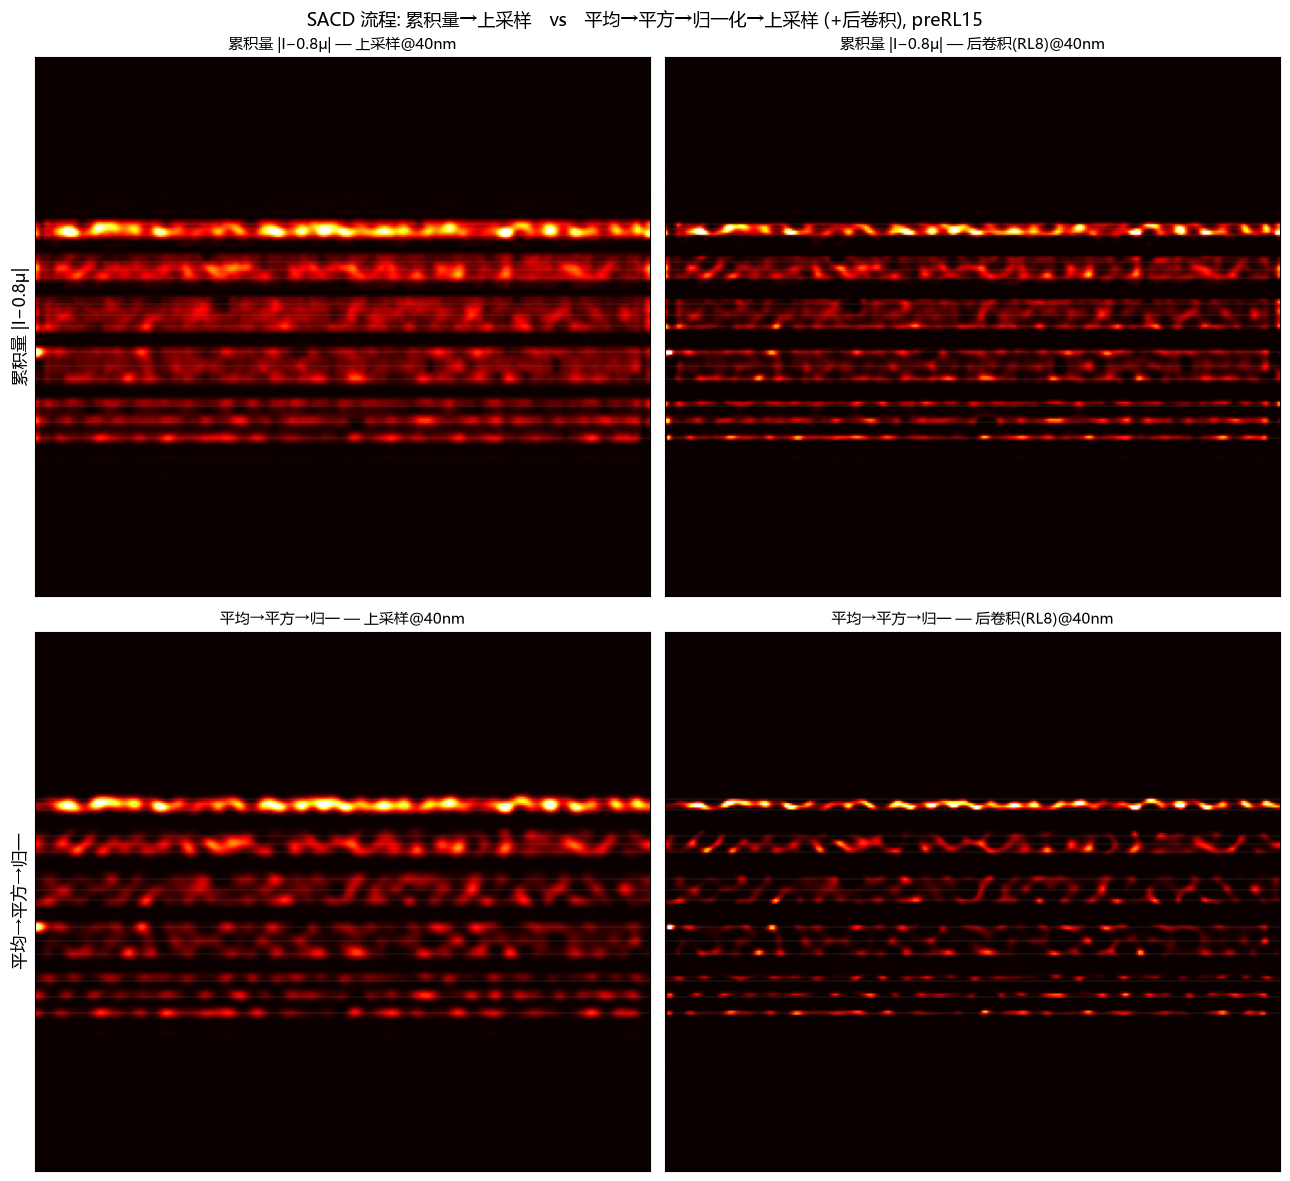

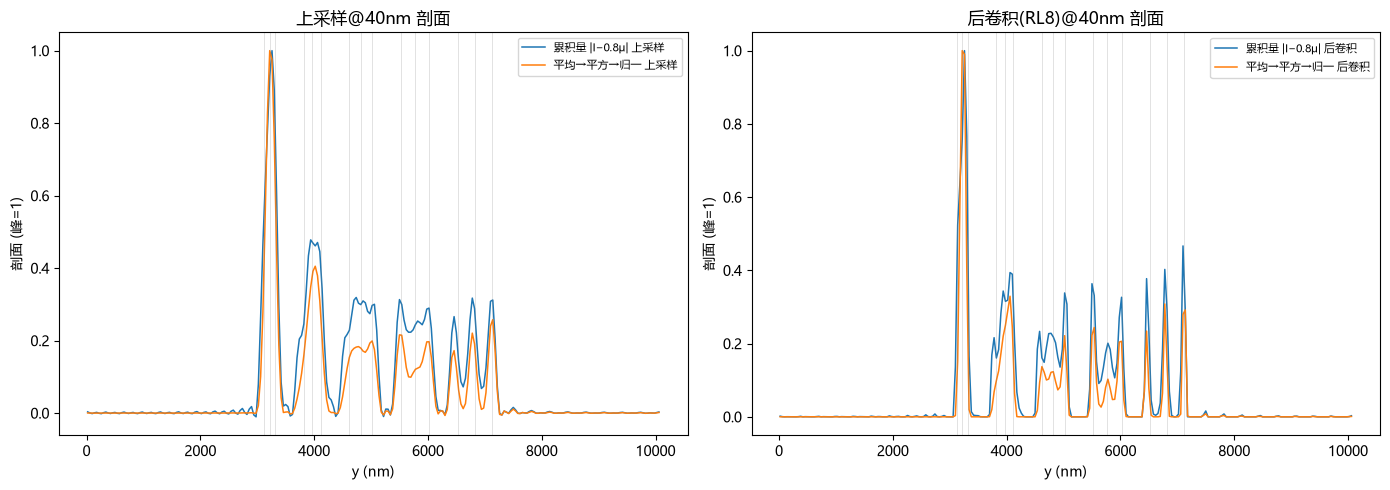

In [11]:
# ============ 对比 3: 累积量→上采样 vs 平均→平方→归一化→上采样 (+后卷积, preRL15) ============
# 复用 UPS[15] (preRL15 上采样结果 @80nm): 只把"累积量"这一步换成
#   "时间平均 → 平方 → 归一化", 其余步骤 (上采样@40nm + 后卷积 RL8) 完全一致。
#   归一化 = 峰值对齐累积量, 使二者送进后置反卷积时尺度一致, 便于公平归因差异。
_UPC = UPS[15].data                                   # @80nm (preRL15 上采样, 已 clip>=0)
PS40 = ried_stack.pixel_size / 4                      # 40nm

# 流程 A (SACD核心): 累积量 |I-0.8μ| 滞后积 → 上采样@40 → 后卷积
_cum80 = np.abs(CumulantSofit(order=SACD_ORDER, lags=tuple(range(SACD_ORDER)),
                              subseq=_UPC.shape[0], subfactor=SACD_SUB,
                              take_abs=True)(_UPC))   # @80
# 流程 B (baseline): 时间平均 μ → 平方 μ² → 归一化(同累积量尺度) → 上采样@40 → 后卷积
_avg80 = _UPC.mean(0)                                 # @80 (时间平均 μ)
_avg_sq = _avg80 ** 2                                 # μ²
_avg_scale = _cum80.max() / max(_avg_sq.max(), 1e-12)  # 归一化因子: 峰值对齐累积量
_avg80n = _avg_sq * _avg_scale                        # @80 (与累积量同尺度)

_cum40 = FourierUpsample(2, lateral=True)(_cum80)      # @40 (未后卷积)
_avg40 = FourierUpsample(2, lateral=True)(_avg80n)     # @40 (未后卷积)
_fcum = RL3D(psf_quad2, iterations=8)(_cum40)          # 后卷积 @40
_favg = RL3D(psf_quad2, iterations=8)(_avg40)          # 后卷积 @40

_PAIRS = [("累积量 |I−0.8μ|", _cum40, _fcum), ("平均→平方→归一", _avg40, _favg)]
print(f"尺度对齐: 累积量峰值={_cum80.max():.3g}, μ²峰值={_avg_sq.max():.3g}, "
      f"归一化因子={_avg_scale:.3g}")
print(f"μ 的 DC: 均值={_avg80.mean():.1f} (μ² 因此带强 DC; 归一化只对齐峰值尺度)")

def _eval3(z, ps):
    """与 GT 对齐 (互相关) 后测每组 3 线调制, 并返回与 GT 的 SSIM。"""
    yv, vv = profile_of(z, ps)
    prof = np.interp(YG, yv, vv)
    g = np.interp(YG, *profile_of(gt_sres, gt_ps))
    cc = np.correlate(prof - prof.mean(), g - g.mean(), mode="full")
    prof = np.roll(prof, -(np.argmax(cc) - (len(cc) // 2)))
    out = {}
    for sg, ys in group_cy.items():
        P = np.mean([np.interp(yy, YG, prof) for yy in ys])
        V = np.mean([np.interp((ys[0] + ys[1]) / 2, YG, prof),
                     np.interp((ys[1] + ys[2]) / 2, YG, prof)])
        out[sg] = (P - V) / (P + V + 1e-12)
    return out, vs_gt(z)

_res = [(n, _eval3(z0, PS40), _eval3(z1, PS40)) for n, z0, z1 in _PAIRS]

print("对比: 累积量 vs 平均→平方→归一化 (preRL15; 仅替换核心一步, 后置完全一致)")
print(f"{'组间距':<8}" + "".join(f"{n+'·上采样':>18}{n+'·后卷积':>18}" for n, *_ in _PAIRS))
for sg in group_cy:
    print(f"{str(sg)+'nm':<8}" + "".join(
        f"{m0[0][sg]:>18.3f}{m1[0][sg]:>18.3f}" for _, m0, m1 in _res))
print("SSIM@GT: " + "   ".join(
    f"{n}: 上采样 {m0[1]:.3f} → 后卷积 {m1[1]:.3f}" for n, m0, m1 in _res))

# ---- 2×2 图: 行 = 累积量 | 平均→平方→归一, 列 = 上采样@40nm | 后卷积@40nm ----
fig, axes = plt.subplots(2, 2, figsize=(13, 12))
for i, (n, z0, z1) in enumerate(_PAIRS):
    for j, z in enumerate((z0, z1)):
        v = np.percentile(z, 99.9)
        axes[i, j].imshow(np.clip(z, 0, v), cmap="hot", aspect="auto",
                          extent=(0, z.shape[1] * PS40, z.shape[0] * PS40, 0))
        axes[i, j].set_title(f"{n} — {'上采样@40nm' if j == 0 else '后卷积(RL8)@40nm'}",
                             fontsize=11)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        for ys in group_cy.values():
            for yy in ys:
                axes[i, j].axhline(yy, color="w", lw=0.3, alpha=0.25)
    axes[i, 0].set_ylabel(n, fontsize=12)
plt.suptitle("SACD 流程: 累积量→上采样　vs　平均→平方→归一化→上采样 (+后卷积), preRL15",
             fontsize=13)
plt.tight_layout(); plt.show()

# ---- 剖面对比: 左 = 上采样@40nm, 右 = 后卷积@40nm ----
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for n, z0, z1 in _PAIRS:
    for a, z, tag in ((axs[0], z0, "上采样"), (axs[1], z1, "后卷积")):
        y, v = profile_of(z, PS40)
        a.plot(y, v / np.max(v), lw=1.1, label=f"{n} {tag}")
for a in axs:
    for ys in group_cy.values():
        for yy in ys:
            a.axvline(yy, color="grey", lw=0.4, alpha=0.4)
    a.set_xlabel("y (nm)"); a.set_ylabel("剖面 (峰=1)"); a.legend(fontsize=8)
axs[0].set_title("上采样@40nm 剖面"); axs[1].set_title("后卷积(RL8)@40nm 剖面")
plt.tight_layout(); plt.show()
